# Robotics: path planning and navigation

Notebook `python/Notebooks/tutorialPathPlanning.ipynb`.

A mobile robot is planned on an occupancy grid by A\*, and a serial robot in joint space by RRT-Connect, both with
`exudyn.robotics.navigation`. The outputs below each cell are those of the last run.

In [1]:
import exudyn as exu
from exudyn.cUtilities import ConvexShape
from exudyn.robotics.models import ManipulatorUR5, LinkDict2Robot
from exudyn.robotics.navigation import OccupancyGrid, PlanGridPath, JointLimits, PlanJointPath, ShortcutPath, TrajectoryFromPath
import numpy as np
import matplotlib.pyplot as plt
import time

## A mobile robot on a grid

The map holds the obstacles in cells. A robot of radius $r$ is a point in the map whose obstacles are grown by $r$
(`Inflate`), so that the planner does not need the shape of the robot.

Text(0.5, 1.0, 'the walls and the inflated map')

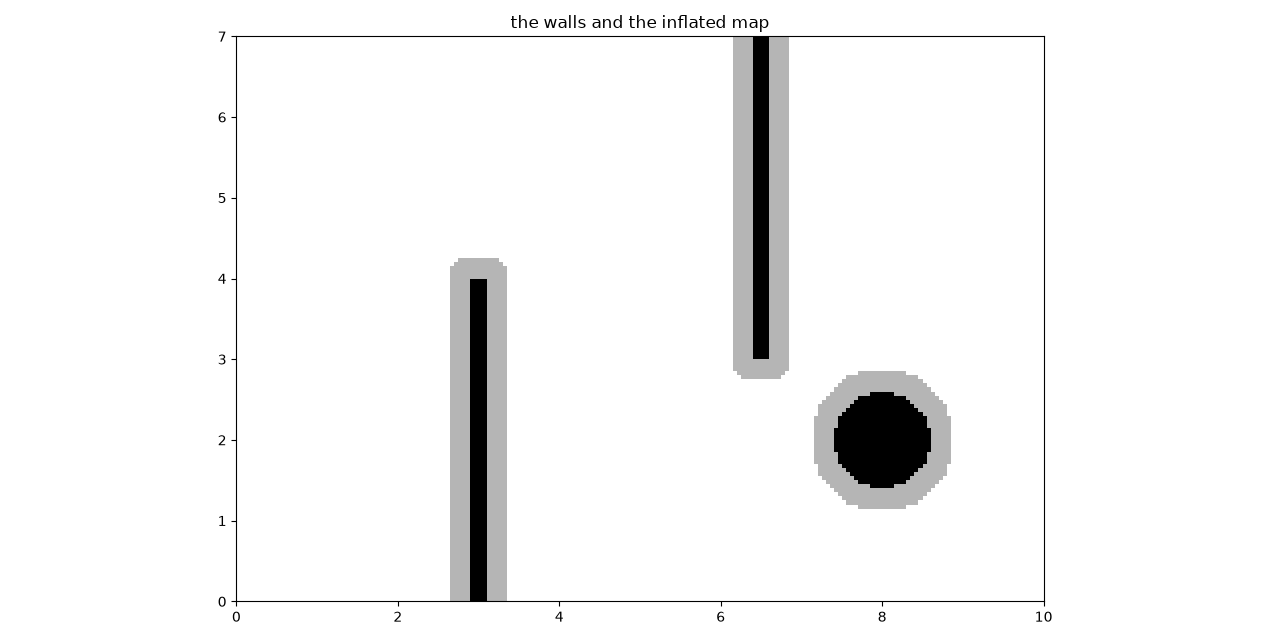

In [2]:
def Map():
    grid = OccupancyGrid([0, 10], [0, 7], 0.05)
    grid.AddRectangle([3, 2], [0.2, 4])
    grid.AddRectangle([6.5, 5], [0.2, 4])
    grid.AddCircle([8, 2], 0.6)
    return grid

grid = Map()
walls = grid.occupied.copy()
grid.Inflate(0.3)
extent = [0, 10, 0, 7]
plt.figure(figsize=(6, 4))
plt.imshow(grid.occupied.T*0.4 + walls.T*0.6, origin='lower', extent=extent, cmap='Greys', vmin=0, vmax=1)
plt.title('the walls and the inflated map')


`PlanGridPath` searches the cells by A\*: it expands the cell with the smallest sum of the cost so far and a lower
bound of the remaining distance. A path of cells is jagged, so that waypoints are left out where the straight line stays free.

cells on the path: 213 , waypoints after the smoothing: 7


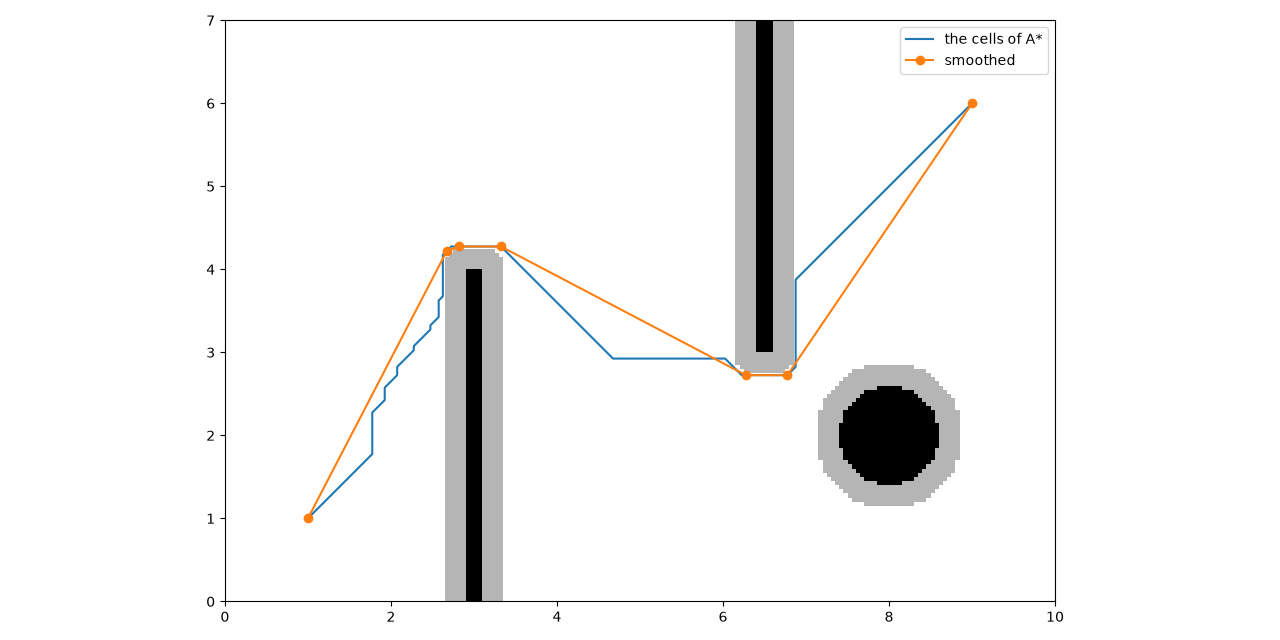

In [3]:
start = [1, 1]
goal = [9, 6]
raw = PlanGridPath(grid, start, goal, smooth=False)
path = PlanGridPath(grid, start, goal)
print('cells on the path:', len(raw), ', waypoints after the smoothing:', len(path))

plt.figure(figsize=(6, 4))
plt.imshow(grid.occupied.T*0.4 + walls.T*0.6, origin='lower', extent=extent, cmap='Greys', vmin=0, vmax=1)
plt.plot(raw[:, 0], raw[:, 1], label='the cells of A*')
plt.plot(path[:, 0], path[:, 1], 'o-', label='smoothed')
plt.legend()


A grid of a serial robot with 6 joints would have far too many cells. A random tree in joint space does not need them.

## A serial robot in joint space

The collision check is done in C++ on capsules of the links. The capsules of neighboring links overlap by their
construction, and the pairs overlapping in a free configuration are left out.

In [4]:
robot = LinkDict2Robot(ManipulatorUR5(), initialConfiguration='model')
qStart = np.array([-0.8, -1.2, 1.2, -1.5, -1.57, 0.])
qGoal = np.array([0.8, -1.2, 1.2, -1.5, -1.57, 0.])
wall = (ConvexShape('Box', size=[0.05, 0.4, 2.]), exu.HT(translation=[0.45, 0, 0.3]))
model = robot.GetCollisionModel(obstacles=[wall], excludeCollidingAt=qStart)
print('start free:', model.IsFree(qStart), ', goal free:', model.IsFree(qGoal), ', straight motion free:', model.IsEdgeFree(qStart, qGoal))
print('minimum distance at the start:', round(model.MinimumDistance(qStart), 4))

start free: True , goal free: True , straight motion free: False
minimum distance at the start: 0.007


RRT-Connect grows a tree from the start and one from the goal until they meet. The path is random and long, and
`ShortcutPath` connects random pairs of its waypoints directly where this is free.

In [5]:
t0 = time.time()
path = PlanJointPath(model, qStart, qGoal, JointLimits(robot), seed=1)
short = ShortcutPath(model, path, seed=1)
print('waypoints of RRT-Connect:', len(path), ', after the shortcuts:', len(short))
print('largest joint motion along the path: %.2f rad, after the shortcuts: %.2f rad' % (np.sum(np.max(np.abs(np.diff(path, axis=0)), axis=1)), np.sum(np.max(np.abs(np.diff(short, axis=0)), axis=1))))

waypoints of RRT-Connect: 40 , after the shortcuts: 9
largest joint motion along the path: 3.81 rad, after the shortcuts: 2.01 rad


`TrajectoryFromPath` makes a trajectory along the path within the limits of the joints: its corners are rounded by
curves, as large as `blendRadius` allows and the obstacles permit, and the robot does not stop at the waypoints. `robot.SetControl(trajectory)` then runs it on a model of the robot, see the example `pathPlanningUR5.py`;
`mobileRobotsNavigation.py` drives a mecanum-wheeled robot and a differential drive.

all configurations free: True


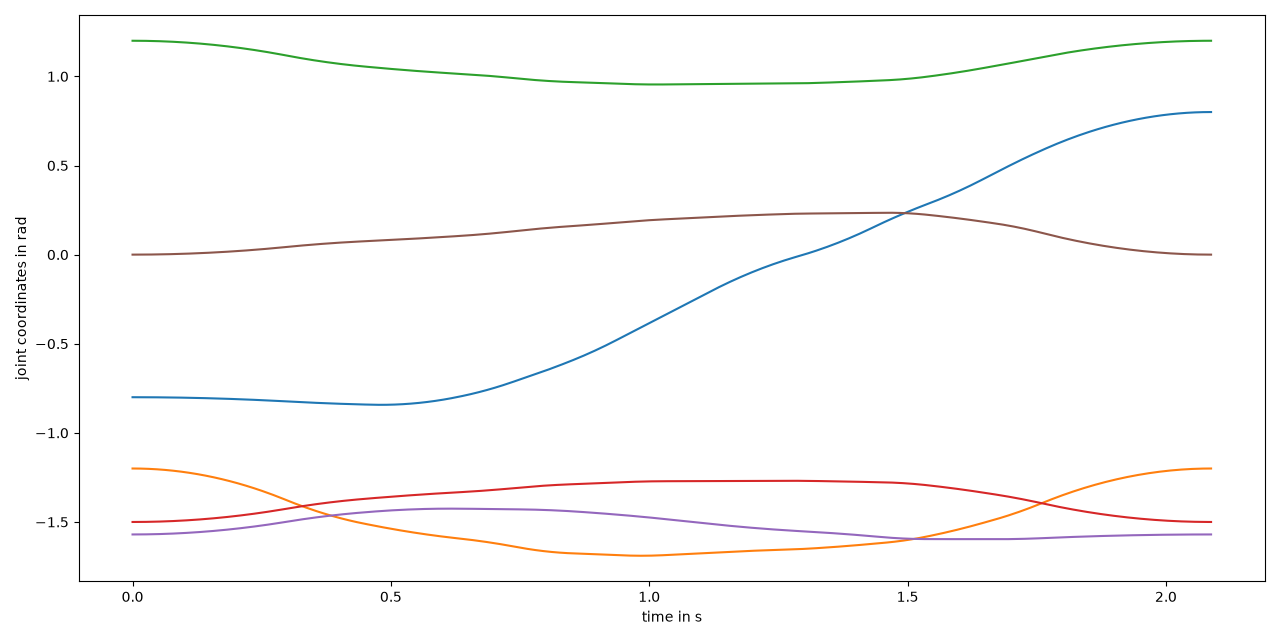

In [6]:
trajectory = TrajectoryFromPath(model, short, [1.5]*6, [4.]*6)
times = np.linspace(0, trajectory.GetTimes()[-1], 400)
q = np.array([trajectory.Evaluate(t)[0] for t in times])
plt.figure(figsize=(6, 3))
plt.plot(times, q)
plt.xlabel('time in s')
plt.ylabel('joint coordinates in rad')
print('all configurations free:', all(model.IsFree(x) for x in q))